# Пол клиента по транзакциям

| | ROC AUC | Accuracy |
|---|---|---|
| Кросс-валидация, train+val (2×5 фолдов) | 0.8907 ± 0.0121 | 0.8044 ± 0.0132 |
| **Test**, 1 680 клиентов, 95% CI | **0.898 [0.883; 0.913]** ✓ | **0.811 [0.793; 0.830]** ✓ |
| Требование задания | > 0.88 | > 0.80 |

**Подход**
1. Клиентские агрегаты (MCC-профиль, суммы, время, динамика) + признаки с метками, считаемые только внутри обучения → LightGBM.
2. Энкодер CoLES: контрастное предобучение GRU на последовательностях транзакций без меток, затем дообучение на пол; его эмбеддинг — ещё и признак для бустинга.
3. TabPFN на отобранных признаках; калиброванный бленд трёх моделей в пространстве логитов, порог 0.5.

**Содержание:** 1. Данные (обзор и качество, разбиение, время, активность, суммы, MCC, терминалы, сила сигнала) ·
2. Подготовка транзакций · 3. Признаки · 4. Признаки с метками · 5. CoLES · 6. Модели и бленд · 7. Финальная оценка ·
8. Выводы

In [1]:
import json
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score

from gender_pred import cli, data, features, plots
from gender_pred.cv import bootstrap_ci
from gender_pred.data import download_data, labels, load_config, prepare_events

RETRAIN = False  # True — полный пересчёт (~25 мин на GPU); False — финальные модели из artifacts/ (GitHub Release)
cfg = load_config("configs/default.yaml", retrain=RETRAIN)
plots.style()
pd.set_option("display.max_columns", 30, "display.width", 200)

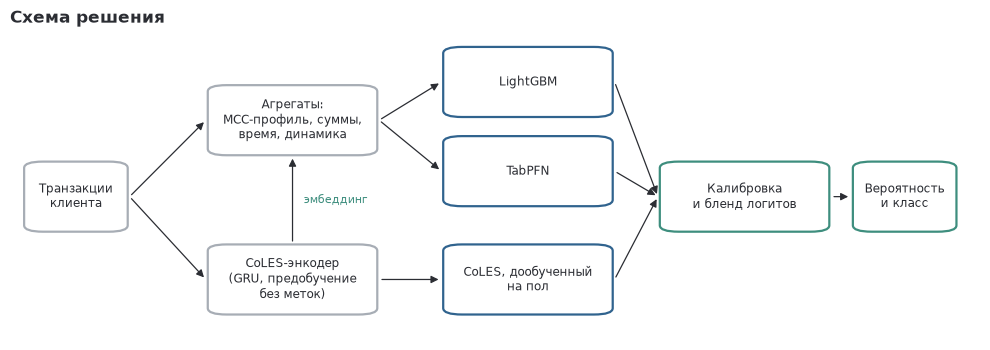

In [2]:
fig = plots.pipeline_schema()

## 1. Данные

**Что за датасет.** Банковские карточные транзакции клиентов с меткой пола — открытый бенчмарк Сбербанка
по предсказанию пола клиента по транзакциям (используется, например, в pytorch-lifestream / CoLES как задача
gender). Версия задания — [`mks-logic/gender_prediction`](https://huggingface.co/datasets/mks-logic/gender_prediction)
на Hugging Face: 8 400 клиентов, разбитых на train / val / test **по клиентам**.

**Постановка.** Классифицируем **клиента**, а не транзакцию: у каждого клиента одна метка пола и история из
десятков–тысяч операций. Всё, что подаётся в модель, — описание клиента целиком (агрегаты по его операциям
или эмбеддинг всей последовательности).

**Как устроен раздел.** Каждый блок: вопрос → код → вывод → решение для пайплайна. Всё, что касается меток, —
только по train (в блоке 1.8 — по train + val, как в кросс-валидации); метки test не используются нигде.
Графики раздела сохраняются в `reports/figures/` командой `make figures`.

In [3]:
download_data(cfg["paths"]["data"])

In [4]:
def load_dataset(splits=["train", "val", "test"], path="data/"):
    dataset = {}
    for split in splits:
        df = pd.read_csv(f"{path}{split}.csv")
        df["term_id"] = df["term_id"].fillna(-1)
        df['gender_desc'] = df.gender.map({0: "женщина", 1: "мужчина"})
        df['tr_datetime'] = pd.to_datetime(df['tr_datetime'], errors='coerce')
        df.sort_values(['customer_id', 'tr_datetime'], inplace=True)
        dataset[split] = df
    return dataset

dataset = load_dataset()

train_df = dataset["train"]
train_df.head(2)

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id,gender,tr_type_desc,mcc_code_desc,gender_desc
0,0,2000-01-01 10:23:26,0,0,-2245.92,-1,1,Оплата услуги. Банкоматы СБ РФ,"Звонки с использованием телефонов, считывающих...",мужчина
1,0,2000-01-02 10:19:29,1,1,56147.89,-1,1,Взнос наличных через АТМ (в своем тер.банке),Финансовые институты — снятие наличности автом...,мужчина


In [5]:
for split in ["train", "test", "val"]:
    print(f"{split.upper()} split: ", dataset[split]["customer_id"].nunique(), " customers")

TRAIN split:  5880  customers
TEST split:  1680  customers
VAL split:  840  customers


### 1.1 Обзор и качество

**Вопрос:** что лежит в колонках, каковы объёмы и баланс классов, насколько данные чистые?

| Колонка | Описание |
|---|---|
| `customer_id` | идентификатор клиента; по нему сделано разбиение на сплиты и агрегация признаков |
| `tr_datetime` | дата и время операции. Даты условные: период начинается 2000-01-01 и длится 457 дней |
| `day` | номер дня от начала периода. В этой версии CSV отдельной колонки нет — день вычисляется из `tr_datetime` при подготовке транзакций (раздел 2) |
| `mcc_code` | MCC — код категории продавца (продукты, одежда, авто, АЗС…), перекодирован в номера |
| `tr_type` | тип операции: покупка, снятие наличных, перевод, зачисление и т. д. |
| `amount` | сумма в условных единицах (отмасштабирована). **Знак: < 0 — расход, > 0 — поступление** |
| `term_id` | идентификатор терминала; пропуск (в шаблоне заменяется на −1) — терминал неизвестен |
| `gender` | целевая метка: 0 — женщина, 1 — мужчина; одна на клиента |
| `tr_type_desc`, `mcc_code_desc` | текстовые описания типа операции и MCC; в признаках не используются, только для подписей |
| `gender_desc` | добавляется в `load_dataset` шаблона: метка словами |

In [6]:
train_df.info(memory_usage="deep", show_counts=True)

<class 'pandas.DataFrame'>
Index: 2613040 entries, 0 to 2613039
Data columns (total 10 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   customer_id    2613040 non-null  int64         
 1   tr_datetime    2613040 non-null  datetime64[us]
 2   mcc_code       2613040 non-null  int64         
 3   tr_type        2613040 non-null  int64         
 4   amount         2613040 non-null  float64       
 5   term_id        2613040 non-null  object        
 6   gender         2613040 non-null  int64         
 7   tr_type_desc   2612068 non-null  str           
 8   mcc_code_desc  2613040 non-null  str           
 9   gender_desc    2613040 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(4), object(1), str(3)
memory usage: 773.6 MB


In [7]:
data.split_overview(dataset, label_splits=("train", "val"))

,строк,клиентов,начало,конец,дней,доля мужчин
train,2613040,5880,2000-01-01,2001-04-01,457,0.439
val,383675,840,2000-01-01,2001-04-01,457,0.425
test,754368,1680,2000-01-01,2001-04-01,457,—


In [8]:
data.category_overview(train_df).to_frame("train")

,train
уникальных MCC,184
уникальных tr_type,74
уникальных терминалов,245165
"клиентов на терминал, медиана",1
доля операций без терминала,0.406
доля расходов (amount < 0),0.82
доля поступлений (amount > 0),0.18


In [9]:
train_df["amount"].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).to_frame("amount (train)").T

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
amount (train),2613040.0,-21616.479498,601617.050289,-1.459845e+08,-3368873.66,-898366.31,-5617.04,631067.7331,3368873.66,1.459845e+08


In [10]:
train_df.isna().sum().to_frame("пропусков").T

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id,gender,tr_type_desc,mcc_code_desc,gender_desc
пропусков,0,0,0,0,0,0,0,972,0,0


In [11]:
data.data_quality(train_df).to_frame("train")

,train
строк,2613040
полных дубликатов строк,7658
нераспознанных дат (NaT),0
клиентов с > 1 значением пола,0
|amount|: 99-й перцентиль,1122957.89
|amount|: 99.9-й перцентиль,4941014.7
|amount|: максимум,145984525.17
доля операций с |amount| > 99.9-го перцентиля,0.001


**Вывод.** 2.6 млн операций у 5 880 клиентов train; мужчин 44% (в val 43%) — классы почти сбалансированы.
Данные чистые: все даты распознаются, у каждого клиента одно значение пола, пропуски — только в текстовом
описании части типов операций. 0.3% строк — полные дубликаты (вероятно, реальные повторные операции при
округлённом времени). Суммы с тяжёлыми хвостами: максимум в ~30 раз больше 99.9-го перцентиля.

**Решение.** Метки берутся на уровне клиента (`labels`: одна на клиента); дубликаты не удаляются — они
одинаково обрабатываются на всех сплитах; суммы используются в виде log(1 + |amount|) и квантилей, а не сырыми;
порог 0.5 и accuracy адекватны при балансе 44 / 56.

### 1.2 Корректность разбиения

**Вопрос:** нет ли клиентов, попавших в несколько сплитов, и похож ли test на train? Если test заметно
отличается, кросс-валидация на train + val не будет репрезентативной.

In [12]:
data.client_overlap(dataset)

,train,val,test
train,5880,0,0
val,0,840,0
test,0,0,1680


**Adversarial validation:** LightGBM учится отличать клиентов train от клиентов test по агрегатам без меток
(5 фолдов). AUC ≈ 0.5 означает, что сплиты неразличимы. Считается в пакете (`cv.adversarial_auc`) и
сохраняется в `results/`.

In [13]:
adv = json.loads(Path("results/adversarial_validation.json").read_text())
print(f"train ({adv['n_a']}) vs test ({adv['n_b']}): AUC = {adv['auc']:.3f} ± {adv['auc_std']:.3f}")
print("самые «различающие» признаки:", ", ".join(adv["top_features"]))

train (5880) vs test (1680): AUC = 0.495 ± 0.017
самые «различающие» признаки: dyn_ac_sum_l30, mcc_la_9, amt_in_la_skew, dyn_w30_out_la_mean, time_hour_8


**Вывод.** Пересечений клиентов нет; adversarial AUC = 0.495 — сплиты неразличимы, сдвига распределения нет. Баланс классов
в train и val одинаков (блок 1.1).

**Решение.** Кросс-валидация на train + val (stratified 5-fold × 2 повтора, по клиентам) — надёжная оценка
качества на test; test открывается один раз в конце.

### 1.3 Время

**Вопрос:** покрывают ли данные весь период, есть ли недельный цикл и аномалии во времени, различается ли
время операций у мужчин и женщин, какова длина истории клиента?

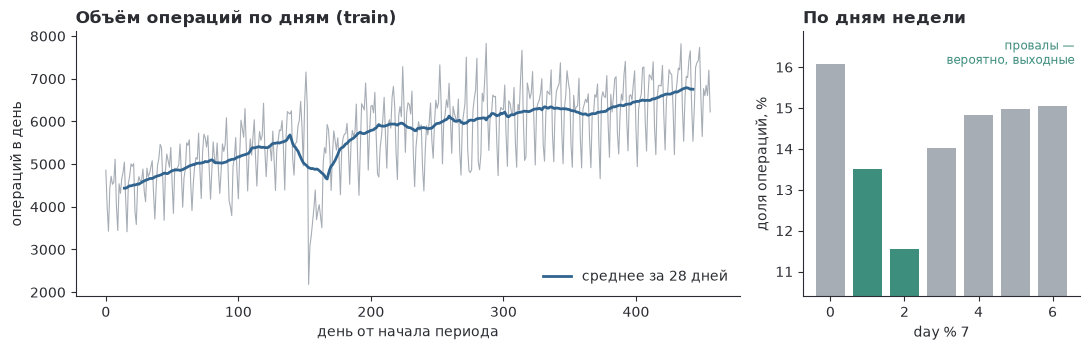

In [14]:
fig = plots.time_volume(train_df)

Период покрыт полностью (457 дней), объём растёт со временем; около 150-го дня — кратковременный провал
(вероятно, сбой выгрузки). Недельный цикл чёткий: по `day % 7` два дня с провалом объёма (1 и 2) —
вероятно, выходные. Поэтому день недели в признаках — как 7 отдельных долей (`time_dow_*`), без
предположения, какие дни выходные.

In [15]:
summary, by_type = data.midnight_check(train_df)
display(summary.to_frame("train"))
by_type

,train
операций в 00:00:00,316243
в среднем за секунду 00:00:01–00:00:59,4.9
в среднем за секунду суток,30.2
доля операций в 00:00:00,0.121


,desc,операций,доля_00,доля всех 00:00:00
tr_type,,,,
6,Покупка. POS ТУ Россия,361872,0.629,0.720
9,Покупка. ТУ Россия,44599,0.737,0.104
25,Покупка. Зарубеж. ТУ,33919,0.936,0.100
7,Возврат покупки. POS ТУ Россия,7677,0.802,0.019
26,Покупка. POS Зарубеж. ТУ,8831,0.690,0.019


**Аномалия 00:00:00.** На ровно 00:00:00 приходится 12% операций — в десятки тысяч раз больше, чем на любую соседнюю
секунду (~5 операций). 72% таких операций — один тип «Покупка. POS ТУ Россия» (и родственные «ТУ» / зарубежные): для этих
каналов время просто не передаётся. Значит, 00:00:00 — это «время неизвестно», а не полночь.

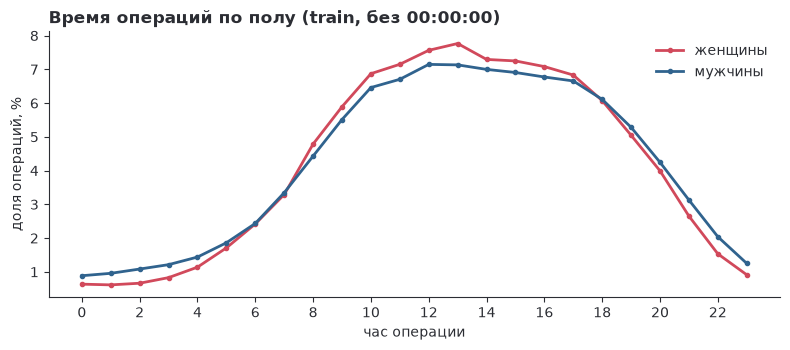

In [16]:
fig = plots.hourly_by_gender(train_df)

In [17]:
data.client_activity(train_df)["длина истории, дней"].describe().round(1).to_frame("train").T

,count,mean,std,min,25%,50%,75%,max
train,5880.0,428.1,68.3,1.0,441.0,453.0,456.0,457.0


**Вывод.** У мужчин больше операций вечером и ночью, у женщин — днём: различие небольшое, но стабильное.
У большинства клиентов история охватывает почти весь период (медиана 453 дня из 457).

**Решение.** Флаг `mid` (время неизвестно): такие операции исключаются из часового профиля, а их доля —
отдельный признак `time_midnight_share`. Часовой профиль — доли по 24 часам, ночь / вечер, циклические
sin / cos. Поскольку истории почти одинаково длинные, окна «последние 30 / 90 / 180 дней» сравнимы между
клиентами.

### 1.4 Активность

**Вопрос:** насколько клиенты различаются по активности и связана ли она с полом?

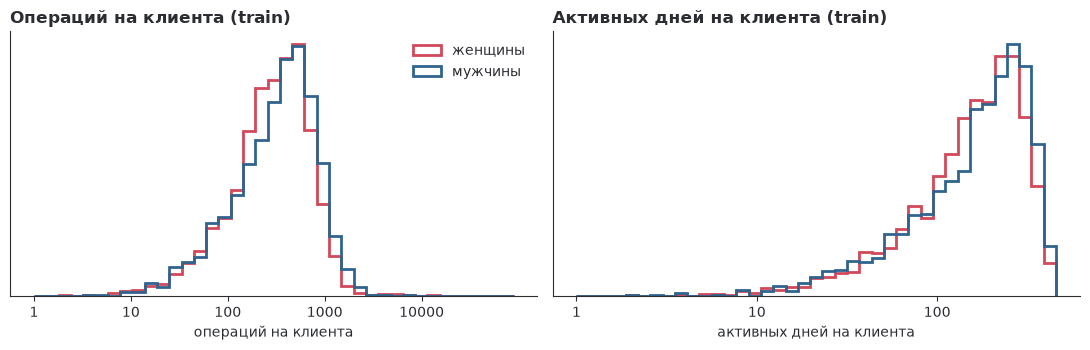

In [18]:
fig = plots.activity_by_gender(train_df)

In [19]:
act = data.client_activity(train_df).join(labels(train_df).map({0: "женщины", 1: "мужчины"}).rename("пол"))
act.groupby("пол")[["операций", "активных дней"]].median()

,операций,активных дней
пол,,
женщины,306.0,166.0
мужчины,356.0,181.0


**Вывод.** Активность различается на порядки (от одной операции до десятков тысяч, медиана ~325), поэтому
шкала логарифмическая. Мужчины чуть активнее (больше операций и активных дней), но распределения сильно
перекрываются — сам по себе объём слабый признак.

**Решение.** Признаки активности логарифмируются, а профили (MCC, типы, часы) считаются как **доли**,
а не счётчики — иначе они в первую очередь отражали бы объём, а не структуру трат. Для последовательной модели
берутся последние 1 200 операций — это вся история у 96% клиентов.

### 1.5 Суммы

**Вопрос:** различаются ли суммы у мужчин и женщин, отдельно для расходов и поступлений; что известно
о масштабировании сумм?

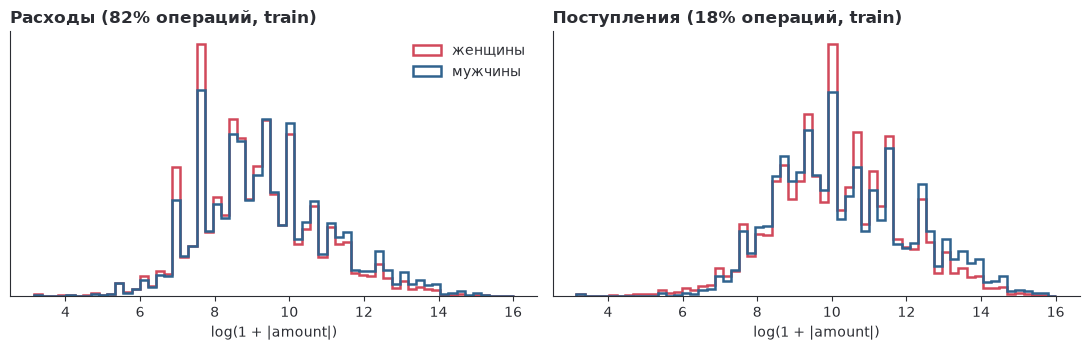

In [20]:
fig = plots.amounts_by_gender(train_df)

In [21]:
unit, in_units = data.amount_scale(train_df)
print(f"самая частая |amount| = {unit}; |amount| в этих единицах (топ-12):")
in_units.to_frame().T

самая частая |amount| = 2245.92; |amount| в этих единицах (топ-12):


amount,1.0,10.0,5.0,0.5,2.0,20.0,3.0,30.0,50.0,40.0,100.0,4.0
операций,161214,101500,92706,80873,74688,61565,53259,49310,48174,31737,31423,30842


In [22]:
rs = data.round_share(train_df, unit)
y_tr = labels(train_df)
print(f"доля операций с целым числом единиц: {(rs * train_df.groupby('customer_id').size()).sum() / len(train_df):.1%}")
print(f"AUC доли «круглых» операций клиента как единственного признака (train): {roc_auc_score(y_tr, rs.reindex(y_tr.index)):.3f}")

доля операций с целым числом единиц: 42.5%
AUC доли «круглых» операций клиента как единственного признака (train): 0.524


**Вывод.** Распределения «гребенчатые» — много типовых сумм. У мужчин чаще крупные расходы и поступления,
у женщин — пики на отдельных типовых суммах. **Масштабирование:** суммы — это исходные суммы, умноженные
на константу (самая частая |amount| ≈ 2245.92 соответствует «1 единице»): в этих единицах значения 1, 10, 5,
0.5, 2, 20, …, и 42.5% операций — целое число единиц. То есть «круглые» суммы восстановимы, но доля
круглых операций клиента сама по себе почти не связана с полом (AUC ≈ 0.52).

**Решение.** Суммы — отдельно для расходов и поступлений (log, квантили, средний чек по MCC, ночной / дневной
расход). Признака «круглая сумма» в модели нет: сигнал слабый (AUC ≈ 0.52); это кандидат в «что дальше»,
а не потеря качества.

### 1.6 MCC и tr_type

**Вопрос:** сколько категорий реально важны, в каких MCC сильнее всего перекос по полу (с поправкой на
поддержку) и насколько MCC и тип операции дублируют друг друга?

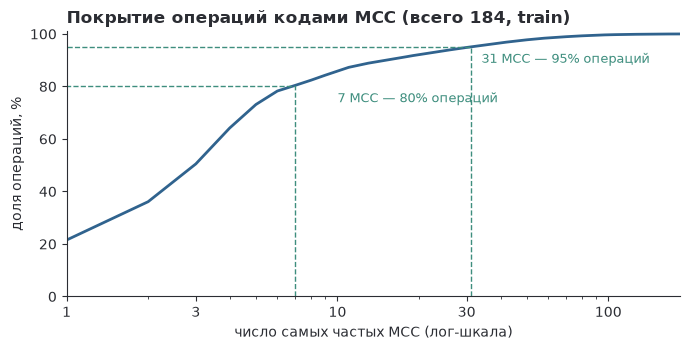

In [23]:
fig = plots.mcc_coverage(train_df)

Семь самых частых MCC покрывают 80% операций, 31 — 95%; остальные ~150 кодов редкие, но именно
в редких (автосервис, женская одежда, рукоделие) — самый сильный перекос по полу:

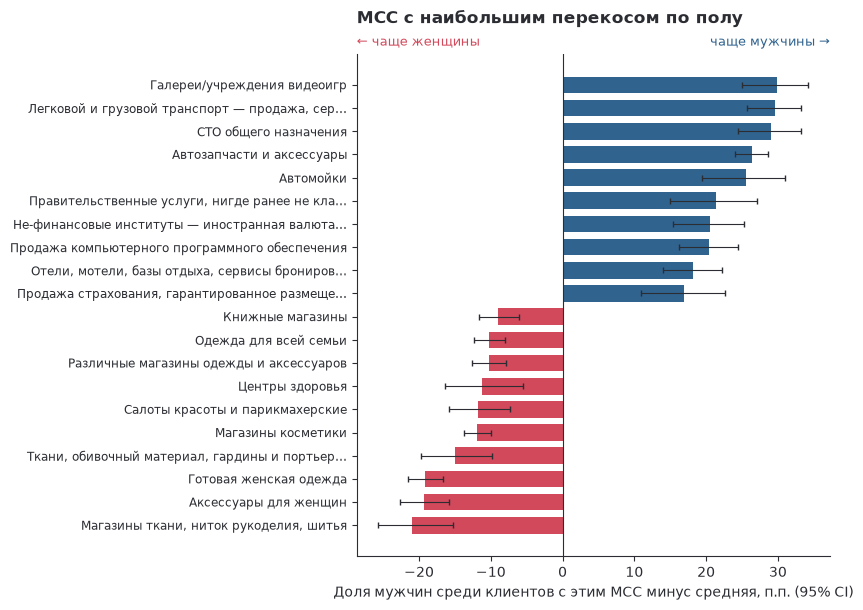

In [24]:
fig = plots.mcc_gender_skew(cfg)

In [25]:
def plot_top_counts(series, top_n=20, xlabel="Count", ylabel=""):
    counts = series.value_counts()
    top_items = counts.nlargest(top_n)
    plt.figure(figsize=(8,6))
    plt.barh(top_items.index, top_items.values)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.show()

In [26]:
data.mcc_trtype_link(train_df).to_frame("train")

,train
"типов операций на MCC, медиана",4
"MCC на тип операции, медиана",1
доля операций с основным типом своего MCC,0.735
доля операций с основным MCC своего типа,0.74


**Вывод.** Перекос по полу сильный и интерпретируемый: «Галереи/учреждения видеоигр» — доля мужчин на
30 п.п. выше средней, «Магазины ткани, ниток рукоделия, шитья» — на 21 п.п. ниже;
показаны только MCC с ≥ 200 клиентами, и 95% интервалы Уилсона не пересекают ноль. MCC и тип операции связаны,
но не дублируют друг друга: у MCC обычно несколько типов операций (медиана 4), у типа операции обычно один MCC.

**Решение.** Профиль трат по MCC — главная группа признаков: доли операций и трат по всем 184 кодам (а не
только частым — сигнал в редких), средний чек по 40 самым частым, TF-IDF + логрег и сглаженный target encoding
(редкие коды стягиваются к среднему). Профиль `tr_type` — отдельная группа того же устройства.

### 1.7 Терминалы

**Вопрос:** можно ли извлечь сигнал из терминалов — сколько клиентов на терминал и пересекаются ли терминалы
train и test? (Без меток test.)

In [27]:
data.terminal_overview(train_df, dataset["test"]).to_frame("значение")

,значение
терминалов в train,245165
"клиентов на терминал, медиана",1
доля терминалов с одним клиентом,0.698
доля операций test на терминалах из train,0.704
доля клиентов test с хотя бы одним терминалом из train,0.993


**Вывод.** Терминалов 245 тыс.; у медианного терминала **один клиент**, 70% терминалов встречаются у одного
клиента. 99% клиентов test хотя бы раз платили в терминалах из train, но общие терминалы — это в основном крупные
сети (у четверти таких операций терминал с > 1 600 клиентами обоих полов): о поле они почти ничего не говорят. 41% операций вообще без терминала.

**Решение.** Терминалы — слабая группа из нескольких статистик без меток (доля операций без терминала,
операций на терминал, концентрация). Target encoding терминалов и граф клиент–терминал проверены парным
сравнением по 10 фолдам — прирост в пределах шума, в модель не вошли.

### 1.8 Сила сигнала групп признаков

**Вопрос:** какие группы признаков без меток реально несут сигнал о поле? LightGBM обучается на каждой
группе отдельно (5 фолдов на train + val, число итераций — по остальным фолдам); результат посчитан
в пакете (`cv.group_signal`) и сохранён в `results/`.

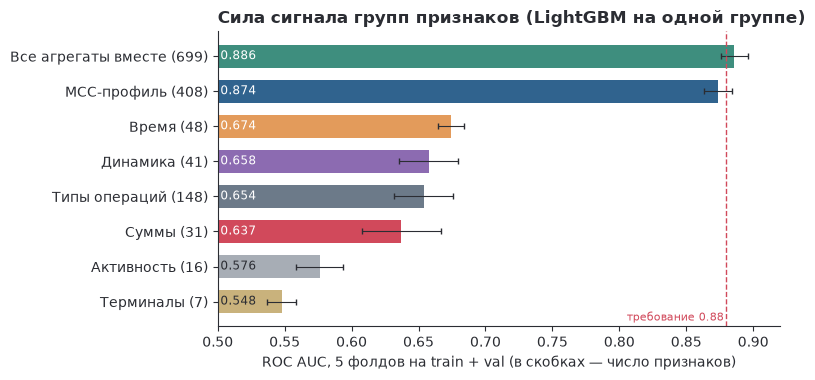

In [28]:
fig = plots.group_signal(cfg)

**Вывод.** Одна группа MCC-профиля даёт AUC 0.874 — почти всё качество: все агрегаты вместе — 0.886. Остальные группы по отдельности слабые: время 0.67, динамика 0.66, типы операций 0.65, суммы 0.64, активность 0.58, терминалы 0.55. Но вместе с MCC они добавляют +0.012, а это больше шума фолдов.

**Решение.** В модель вошли все группы (LightGBM сам отбирает полезное), а основная работа над признаками
пошла в профиль трат: TF-IDF + логрег и target encoding MCC (раздел 4) и последовательная модель CoLES
(раздел 5), которая видит порядок операций.

### 1.9 Итог: наблюдение → решение → чем подтверждено

| Наблюдение | Решение в пайплайне | Чем подтверждено |
|---|---|---|
| Классификация клиента; разбиение по клиентам, пересечений нет | всё агрегируется до клиента; CV — stratified по клиентам на train + val | `client_overlap` = 0 (1.2) |
| Test не отличается от train | CV на train + val как оценка качества; test — один раз | adversarial AUC = 0.495 (1.2) |
| 12% операций в 00:00:00 — время не передаётся для части каналов | флаг `mid`, исключение из часового профиля, доля — отдельный признак | в ~60 000 раз больше соседних секунд, 72% — один тип операции (1.3) |
| Чёткий недельный цикл, неизвестно, какие дни выходные | 7 долей по `day % 7` вместо флага «выходной» | провалы объёма на днях 1 и 2 (1.3) |
| Активность различается на порядки | доли вместо счётчиков; log активности; окна 30 / 90 / 180 дней | распределения на лог-шкале (1.4) |
| Тяжёлые хвосты сумм; суммы = исходные × константа | log(1 + \|amount\|), квантили, отдельно расходы / поступления; без признака «круглая сумма» | максимум ≈ 30 × p99.9 (1.1); AUC доли круглых ≈ 0.52 (1.5) |
| Сильнейший перекос — в редких MCC | доли по всем 184 MCC, TF-IDF + логрег, сглаженный target encoding | интервалы Уилсона (1.6); AUC группы MCC (1.8) |
| Один клиент на терминал | только общие статистики терминалов | TE терминалов и граф — в пределах шума по 10 фолдам (1.7) |
| Профиль трат — главный сигнал, остальное слабее | ставка на MCC-признаки и CoLES; бленд с TabPFN | AUC по группам (1.8), вклад компонентов (раздел 6) |

### Бейзлайн задания

In [29]:
def baseline_aggregation(df):
    tx_stats = df.groupby('customer_id').agg({
        'amount': ['count', 'sum'],
        'mcc_code': pd.Series.nunique,
        'tr_type': pd.Series.nunique,
    })
    tx_stats.columns = [f'base_{k}_{stat}' for k, stat in tx_stats.columns]
    tx_stats.reset_index(inplace=True)

    target = df[['customer_id', 'gender']].drop_duplicates()
    features = tx_stats.merge(target, on='customer_id', how='left')

    X = features.drop(columns=['customer_id', 'gender'])
    y = features['gender']

    return X, y

X_train, y_train = baseline_aggregation(dataset["train"])
X_test, y_test = baseline_aggregation(dataset["test"])
X_val, y_val = baseline_aggregation(dataset["val"])

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, average_precision_score,
    precision_score, recall_score
)

def eval(y_val, y_pred, y_pred_proba):
    auc = roc_auc_score(y_val, y_pred_proba)
    acc = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)

    return {
        "auc_score": auc,
        "accuracy_score": acc,
        "precision_score": precision,
        "recall_score": recall
    }

def fit_predict_rf(X_train, y_train, X_val, y_val, X_test):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    y_pred_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_proba >= 0.5).astype(int)

    return y_pred_proba, y_pred

y_pred_proba, y_pred = fit_predict_rf(X_train, y_train, X_val, y_val, X_test)
metrics = eval(y_test, y_pred, y_pred_proba)
metrics

{'auc_score': 0.5737087280045527,
 'accuracy_score': 0.5577380952380953,
 'precision_score': 0.5238095238095238,
 'recall_score': 0.4269081500646831}

## 2. Подготовка транзакций

`prepare_events` переводит сырые строки в компактный вид, общий для агрегатов и последовательной модели:
день от начала периода, час и день недели, флаг неизвестного времени, знак и логарифм суммы, терминал
(−1 — неизвестен). Ниже — три операции одного клиента до и после (последняя — со временем 00:00:00).

In [31]:
one = train_df[train_df["customer_id"] == train_df["customer_id"].iloc[0]]
at_midnight = one["tr_datetime"] == one["tr_datetime"].dt.normalize()
rows = pd.concat([one[~at_midnight].head(2), one[at_midnight].head(1)])
rows[["customer_id", "tr_datetime", "mcc_code", "tr_type", "amount", "term_id"]]

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id
0,0,2000-01-01 10:23:26,0,0,-2245.92,-1
1,0,2000-01-02 10:19:29,1,1,56147.89,-1
28,0,2000-01-16 00:00:00,8,6,-6288.56,-1


In [32]:
prepare_events(rows)[["cid", "mcc", "tt", "la", "out", "term", "day", "hour", "dow", "mid"]]

,cid,mcc,tt,la,out,term,day,hour,dow,mid
0,0,0,0,7.717316,True,-1,0,10,0,False
1,0,1,1,10.935762,False,-1,1,10,1,False
2,0,8,6,8.746646,True,-1,15,0,1,True


`la` = log(1 + |amount|), `out` — расход, `day` — номер дня, `hour` / `dow` — час и день недели, `mid` — время
неизвестно (час для таких операций в признаках не учитывается). Для последовательной модели из этих полей
дополнительно строятся знаковая лог-сумма и логарифм интервала до предыдущей операции.

## 3. Признаки

Энкодер CoLES нужен уже здесь: его эмбеддинг клиента входит в признаки. При `RETRAIN = False` энкодер и
финальные модели загружаются из `artifacts/` (архив из GitHub Release), при `True` — обучаются заново.

In [33]:
ctx = cli.build_context(cfg, dataset, log=False)
print(f"устройство: {ctx.device}; клиентов с последовательностями: {len(ctx.seqs.ids)}")

устройство: cuda; клиентов с последовательностями: 8400


Функции шаблона: `generate_features` считает признаки одного сплита (вызывается отдельно на train / val / test),
`fit_predict_proba` обучает модель на train+val и предсказывает test. Обе — тонкие обёртки над пакетом.

In [34]:
def generate_features(df):
    """Агрегаты клиента + эмбеддинг CoLES (index = customer_id); последовательности — в хранилище пакета."""
    X = ctx.features(df)
    y = labels(df).reindex(X.index)
    return X, y


def fit_predict_proba(X_train, y_train, X_val, y_val, X_test):
    """LightGBM + дообученный CoLES + TabPFN, калиброванный бленд; порог 0.5."""
    return cli.fit_predict(ctx, X_train, y_train, X_val, y_val, X_test)

In [35]:
X_train, y_train = generate_features(dataset["train"])
X_train.shape

(5880, 2165)

Признаки без меток — одинаковые колонки на любом сплите: словари MCC и типов операций фиксируются по train.
`raw_` — счётчики операций и сумм по каждому MCC / типу (вход для признаков с метками, раздел 4; в бустинг
напрямую не идут), `emb_` — эмбеддинг CoLES (раздел 5).

In [36]:
features.feature_groups(X_train)

,группа,префикс,признаков,примеры
0,Активность,act_,16,"act_n_tr, act_n_tt, act_gap_mean"
1,Суммы,amt_,31,"amt_out_cnt, amt_out_la_q75, amt_in_la_skew"
2,MCC-профиль,mcc_,408,"mcc_cnt_0, mcc_cnt_136, mcc_sum_88"
3,Типы операций,tt_,148,"tt_cnt_0, tt_cnt_49, tt_sum_24"
4,Время,time_,48,"time_hour_0, time_hour_16, time_dow_sum_1"
5,Терминалы,term_,7,"term_na_share, term_tr_per_term, term_top3_share"
6,Динамика,dyn_,41,"dyn_mcc_cnt_hhi, dyn_out_frac_ewm30, dyn_w30_o..."
7,Счётчики,raw_,442,"raw_mcccnt_0, raw_mcccnt_147, raw_mccsum_110"
8,Эмбеддинги CoLES,emb_,1024,"emb_0, emb_341, emb_682"


In [37]:
clients = X_train.index[:3]
cols = ["act_n_tr", "amt_out_la_mean", "amt_in_cnt_share", "mcc_cnt_0", "time_night_share",
        "time_midnight_share", "term_na_share", "dyn_mcc_cnt_hhi", "emb_0"]
X_train.loc[clients, cols].round(3)

,act_n_tr,amt_out_la_mean,amt_in_cnt_share,mcc_cnt_0,time_night_share,time_midnight_share,term_na_share,dyn_mcc_cnt_hhi,emb_0
customer_id,,,,,,,,,
0,1046.0,8.439,0.039,0.132,0.082,0.198,0.360,0.233,-0.046
2,132.0,10.080,0.076,0.348,0.288,0.000,0.386,0.442,0.008
3,855.0,9.217,0.062,0.049,0.133,0.013,0.460,0.089,-0.046


**Вывод.** Больше всего gain у групп «линейные модели (TF-IDF, CoLES)» (27%), «MCC-профиль» (19%) и «target encoding» (18%); терминалы почти не используются (1.3%). Распределение gain по группам — в разделе 6.

## 4. Признаки с метками

Часть признаков использует метку пола: target encoding MCC и типов операций (доля мужчин среди операций
с этим кодом, сглаженная к среднему), логистическая регрессия по TF-IDF профиля трат и логистическая
регрессия по эмбеддингу CoLES. Если посчитать их по всем клиентам и тут же обучить на них бустинг, клиент
«увидит» собственную метку — утечка.

Поэтому они считаются **out-of-fold** и **только внутри обучения**:
- для обучающих клиентов — по внутренним фолдам: значение клиента считает модель, обученная на остальных
  4/5 обучающих клиентов, без его метки;
- для новых клиентов (фолд валидации в CV, test в финале) — по статистикам, посчитанным на всех обучающих.

Test в расчёте не участвует: его метки не используются нигде, а сами признаки для test считаются только
применением уже обученных статистик. Ниже — тот же расчёт на train (в финальной модели — на train+val).

In [38]:
lf = features.LabelFeatures(cfg["features"], seed=0, n_inner=cfg["cv"]["inner_splits"])
L_train = lf.fit_transform(X_train, y_train)
print(L_train.shape)
L_train.loc[clients, ["te_mcc_wmean", "te_mcc_lo_sum", "te_tt_wmean", "lr_tfidf", "lr_emb"]].round(3)

(5880, 20)


,te_mcc_wmean,te_mcc_lo_sum,te_tt_wmean,lr_tfidf,lr_emb
customer_id,,,,,
0,0.450,0.536,0.439,-0.500,0.184
2,0.439,0.001,0.440,-0.591,0.881
3,0.447,3.773,0.441,0.805,-1.030


In [39]:
pd.Series({c: roc_auc_score(y_train, L_train[c]) for c in ["te_mcc_wmean", "te_tt_wmean", "lr_tfidf", "lr_emb"]},
          name="OOF AUC на train").round(4).to_frame().T

,te_mcc_wmean,te_tt_wmean,lr_tfidf,lr_emb
OOF AUC на train,0.7849,0.5659,0.8615,0.8575


Каждый из этих признаков в одиночку — сильный предиктор, при этом значения out-of-fold, то есть
честные: на новых клиентах они ведут себя так же.

## 5. CoLES

Энкодер — GRU над транзакциями (MCC, тип операции, знаковая лог-сумма, час, день недели, интервал между
операциями). Предобучение без меток (CoLES): случайные срезы одного клиента сближаются в пространстве
эмбеддингов, срезы разных клиентов — отталкиваются. Затем энкодер (а) даёт эмбеддинг клиента и (б)
дообучается на пол. Для предобучения используются только клиенты train и val.

In [40]:
enc = cfg["sequence"]["encoder"]
emb = X_train.filter(like="emb_")
print(f"конфигурация энкодера: {enc}")
print(f"эмбеддинг клиента: {emb.shape[1]} чисел; матрица train: {emb.shape}")

конфигурация энкодера: {'hidden': 1024, 'mcc_dim': 48, 'tr_type_dim': 24, 'use_time': True, 'emb_noise': 0.003}
эмбеддинг клиента: 1024 чисел; матрица train: (5880, 1024)


In [41]:
cv_models = pd.read_csv("results/cv_models.csv").set_index("model")
cv_models.loc[[i for i in cv_models.index if "CoLES" in i]].round(4)

,auc,auc_std,accuracy,accuracy_std
model,,,,
"Эмбеддинг CoLES (1024), логрег",0.8599,0.0145,0.7767,0.0166
"LightGBM, агрегаты + признак CoLES",0.8900,0.0119,0.8028,0.0127
"CoLES, дообученный на пол",0.8664,0.0135,0.7815,0.0144


**Вывод.** Эмбеддинг CoLES с логистической регрессией даёт на кросс-валидации AUC 0.860,
дообученный на пол энкодер — 0.866: меньше, чем агрегаты с LightGBM (0.888), но сигнал
частично независимый (порядок и ритм операций), и в бленде он стабильно добавляет качество (раздел 6).
В двумерной проекции (UMAP) пол визуально не разделяется — сигнал распределён по многим измерениям,
поэтому проекцию не показываем.

## 6. Модели и бленд

Все модели оцениваются на одной кросс-валидации (train+val, stratified 5-fold × 2 повтора). Для каждой
отдельной модели калибровка (Platt) подбирается по остальным фолдам, accuracy — при пороге 0.5; для
бленда так же подбираются веса. Число итераций бустинга — тоже по остальным фолдам.

In [42]:
t = cv_models.copy()
pd.DataFrame({
    "ROC AUC": t["auc"].map("{:.4f}".format) + " ± " + t["auc_std"].map("{:.4f}".format),
    "accuracy": t["accuracy"].map("{:.4f}".format) + " ± " + t["accuracy_std"].map("{:.4f}".format),
})

,ROC AUC,accuracy
model,,
"Эмбеддинг CoLES (1024), логрег",0.8599 ± 0.0145,0.7767 ± 0.0166
"LightGBM, агрегаты",0.8884 ± 0.0112,0.8028 ± 0.0125
"LightGBM, агрегаты + признак CoLES",0.8900 ± 0.0119,0.8028 ± 0.0127
"CoLES, дообученный на пол",0.8664 ± 0.0135,0.7815 ± 0.0144
"TabPFN v2, 300 признаков",0.8874 ± 0.0124,0.8001 ± 0.0132
Бленд = итог,0.8907 ± 0.0121,0.8044 ± 0.0132


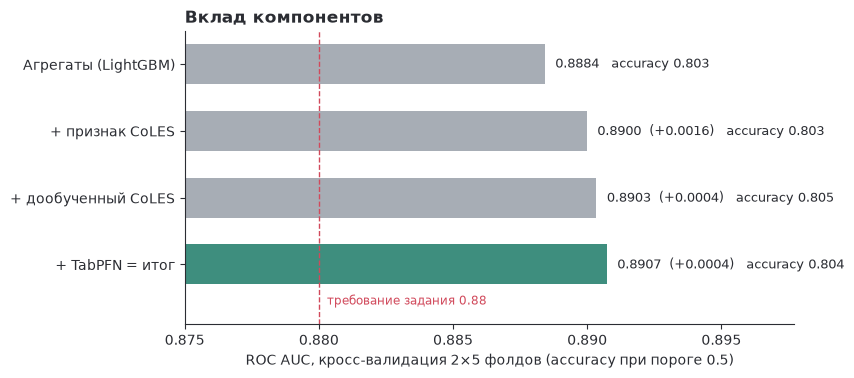

In [43]:
fig = plots.component_contribution(cfg)

**Вывод.** Агрегаты с LightGBM дают 0.8884; признак CoLES и дообученный энкодер добавляют
сигнал о порядке операций, которого нет в агрегатах; TabPFN в одиночку почти на уровне LightGBM и добавляет
разнообразия. Итог — **0.8907** (accuracy 0.804).
Веса бленда: gbm 0.70, seq 0.10, tabpfn 0.20. Каждое добавление проверялось парным сравнением по
10 фолдам.

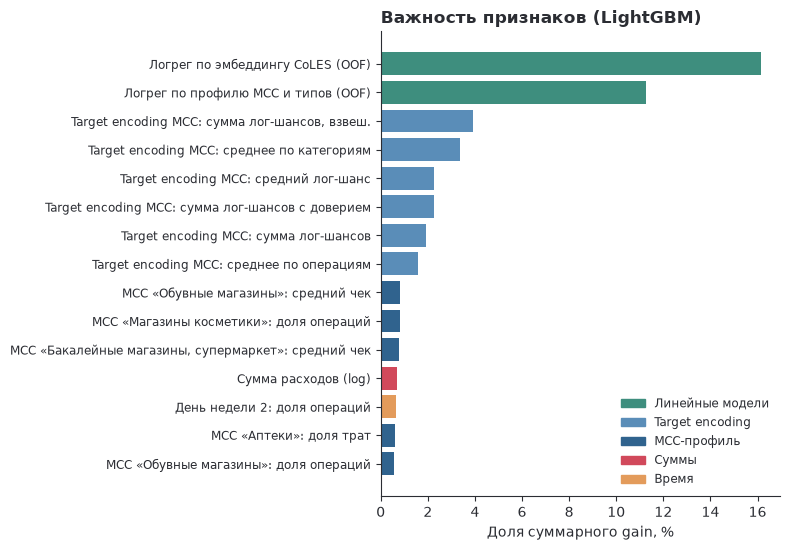

In [44]:
fig = plots.feature_importance(cfg)

**Вывод.** Сильнейшие признаки — сводные оценки профиля трат (логрег по TF-IDF MCC, target encoding MCC)
и доли конкретных MCC; заметный вклад у времени операций и динамики трат. Топ-15 признаков дают
48% суммарного gain.

**Проверено и не вошло:** target encoding по терминалам и граф клиент–терминал, CatBoost и XGBoost,
дополнительные статистики концентрации и ритма трат — прирост в пределах шума фолдов.

## 7. Финальная оценка

Ячейка шаблона: признаки считаются на каждом сплите отдельно, модель обучается на train+val, test только
предсказывается. При `RETRAIN = False` загружаются финальные модели из `artifacts/`.

In [45]:
# Feature engineering
X_train, y_train = generate_features(dataset["train"])
X_test, y_test = generate_features(dataset["test"])
X_val, y_val = generate_features(dataset["val"])

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

# Model training and prediction
y_pred_proba, y_pred = fit_predict_proba(X_train, y_train, X_val, y_val, X_test)

# Evaluation
metrics = eval(y_test, y_pred, y_pred_proba)
metrics

{'auc_score': 0.8979020440415284,
 'accuracy_score': 0.8113095238095238,
 'precision_score': 0.8343108504398827,
 'recall_score': 0.7360931435963778}

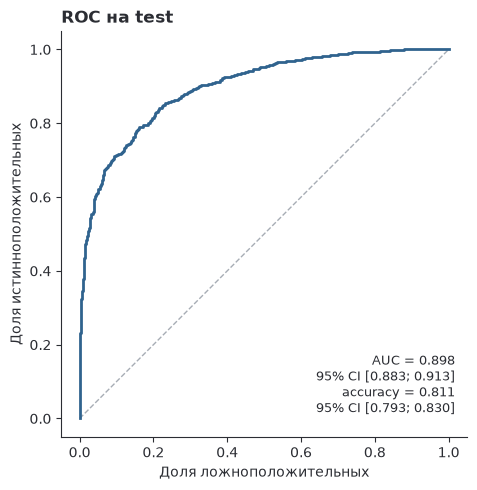

In [46]:
m = bootstrap_ci(y_test.to_numpy(), y_pred_proba, threshold=0.5, n=cfg["report"]["bootstrap"])
pd.DataFrame({"gender": y_test.to_numpy(), "proba": y_pred_proba}, index=y_test.index).to_parquet(
    "results/test_predictions.parquet")
fig = plots.roc_test(cfg)

**Вывод.** На test AUC = **0.8979** (95% CI 0.883–0.913),
accuracy = **0.8113** (95% CI 0.793–0.830):
требования ✓ AUC > 0.88 и ✓ accuracy > 0.80.
Ширина интервалов (±0.015 по AUC на 1 680 клиентах) больше, чем
разница между сильными вариантами модели, поэтому решения принимались только по кросс-валидации.

## 8. Выводы

- Решающий сигнал — **профиль трат по MCC**: одна эта группа поднимает AUC с ~0.67 до ~0.88; остальные
  агрегаты и модели добавляют ещё ≈ 0.011.
- **CoLES** полезен как дополнение к агрегатам (эмбеддинг-признак и дообученная модель в бленде), но не как
  замена: на 8 400 клиентах предобучению не хватает объёма неразмеченных последовательностей.
- **Бленд в пространстве логитов с калибровкой** даёт честные вероятности, поэтому порог 0.5 оптимален для
  accuracy без подбора на test.
- Test открывался один раз, на зафиксированной модели; итог: AUC 0.8979, accuracy 0.8113.
- Что дальше: больше неразмеченных последовательностей для предобучения CoLES, трансформер вместо GRU,
  мультизадачное дообучение (пол + возраст/доход при наличии разметки).